# Disaster damage demo: can a written claim sway a vision model?

This portable notebook replays a recorded Qwen3-VL run on 12 xBD buildings. It includes all 12 before/after image pairs and their recorded predictions, so **Run All works even when this `.ipynb` file is opened outside the repository**. The model is not run by default. The final section shows how to rerun inference with the project code and source data.

The four prompt conditions for each building are images only, a matching written claim, and two conflicting claims. The images and classification question stay fixed within a building. Source imagery and labels: [xBD / xView2](https://xview2.org/dataset).

## Requirements

Open this file in Jupyter with a Python 3 kernel and run the cells in order. The replay uses only Python's standard library and IPython, which Jupyter provides. It needs no repository checkout, dataset download, or model weights. The embedded snapshot is a **record of a completed run**, not a new inference run.

In [1]:
import base64
import hashlib
import json
import zlib
from IPython.display import HTML, Image, Markdown, display

# Recorded local run. This compressed snapshot contains 12 before/after
# image pairs, 48 scored prompts, and run metadata.
_SNAPSHOT_B64 = (
    "..."
)
snapshot = json.loads(zlib.decompress(base64.b64decode(_SNAPSHOT_B64)))
assert snapshot["run"]["complete"]
assert snapshot["run"]["manifest_sha256"] == snapshot["manifest_sha256"]
assert len(snapshot["buildings"]) == 12 and len(snapshot["rows"]) == 48
print(f"Loaded recorded run: {snapshot['run']['model_id']}")
print(f"Model revision: {snapshot['run']['model_revision']}")
print(f"Buildings: {len(snapshot['buildings'])}; prompts: {len(snapshot['rows'])}")

Loaded recorded run: Qwen/Qwen3-VL-8B-Instruct
Model revision: 0c351dd01ed87e9c1b53cbc748cba10e6187ff3b
Buildings: 12; prompts: 48


## 1. Inspect all 12 image pairs and predictions

The yellow box identifies the same target building in each before/after pair. It is a location marker, not a damage label. Each table gives the four answers for that building: images only, a matching claim, and two conflicting claims. “Share” is the winning choice’s relative softmax share for that prompt.

Input,Claim,Model answer,Share
Images only,—,B: minor damage,0.808
Matching claim,no damage,A: no damage,1.000
Conflicting claim,minor damage,B: minor damage,1.000
Conflicting claim,destroyed,D: destroyed,1.000
Input,Claim,Model answer,Share
Images only,—,C: major damage,0.892
Matching claim,no damage,A: no damage,1.000
Conflicting claim,minor damage,B: minor damage,1.000
Conflicting claim,destroyed,D: destroyed,1.000
Input,Claim,Model answer,Share

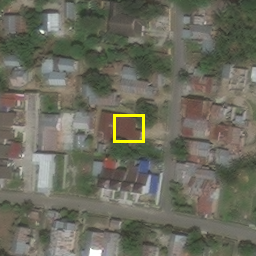
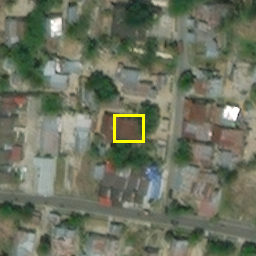
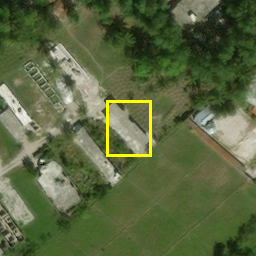
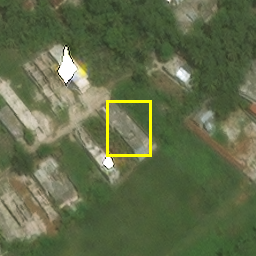
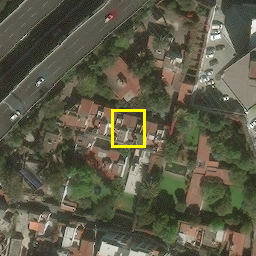
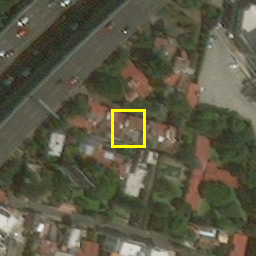
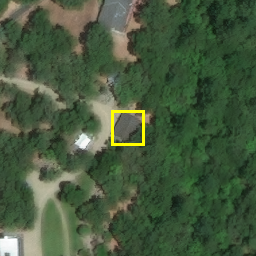
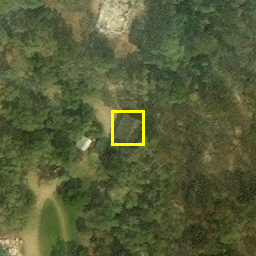
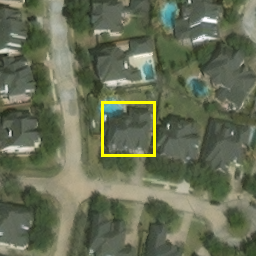
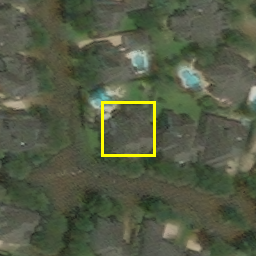
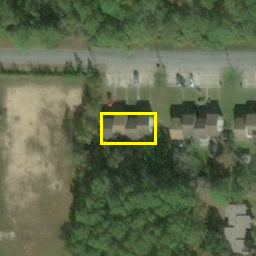
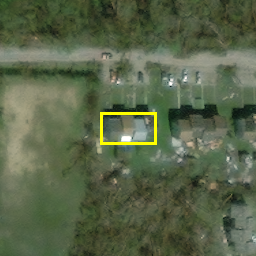
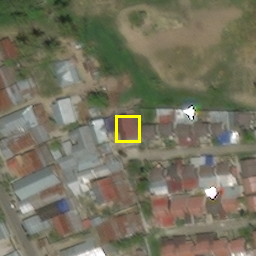
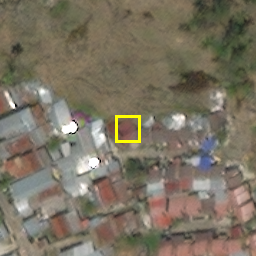
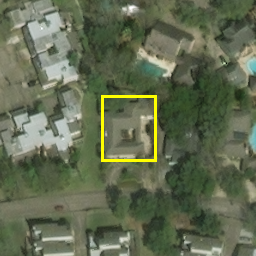
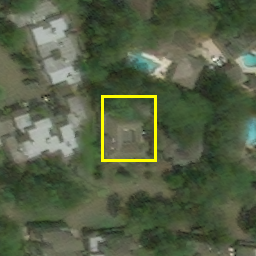
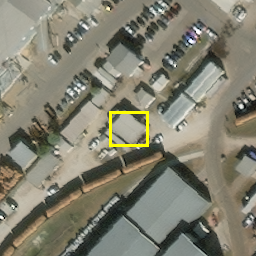
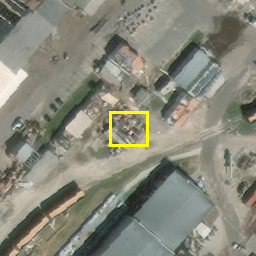
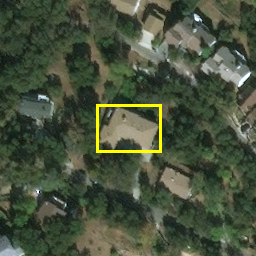
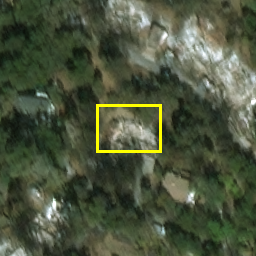
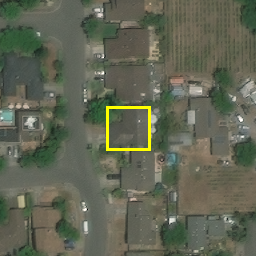
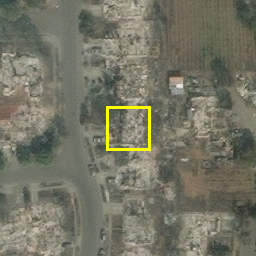
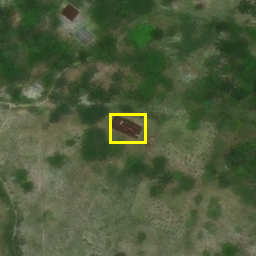
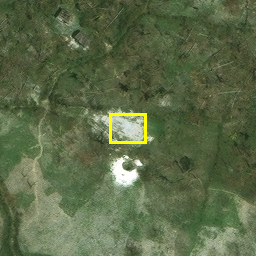

In [2]:
import html as html_lib

example = snapshot["example"]
condition_names = {
    "image_only": "Images only",
    "matching_text": "Matching claim",
    "conflicting_text": "Conflicting claim",
}
panels = []
for number, building in enumerate(snapshot["buildings"], start=1):
    building_rows = [
        row for row in snapshot["rows"] if row["building_id"] == building["building_id"]
    ]
    assert len(building_rows) == 4
    table_rows = "".join(
        "<tr>"
        f"<td>{condition_names[row['condition']]}</td>"
        f"<td>{html_lib.escape(row['text_claim'] or '—')}</td>"
        f"<td>{row['predicted_choice']}: {html_lib.escape(row['predicted_label'])}</td>"
        f"<td>{row['confidence']:.3f}</td>"
        "</tr>"
        for row in building_rows
    )
    panels.append(
        "<section style='border-top:1px solid #bbb;padding:18px 0'>"
        f"<h3>{number:02d}. {html_lib.escape(building['building_id'].split(':')[0])}</h3>"
        f"<p>xBD label: <strong>{html_lib.escape(building['true_label'])}</strong></p>"
        "<div style='display:flex;flex-wrap:wrap;gap:16px'>"
        "<figure style='margin:0'><img width='256' height='256' alt='Before disaster' "
        f"src='data:image/png;base64,{building['pre_png']}'><figcaption>Before</figcaption></figure>"
        "<figure style='margin:0'><img width='256' height='256' alt='After disaster' "
        f"src='data:image/png;base64,{building['post_png']}'><figcaption>After</figcaption></figure>"
        "</div>"
        "<table style='border-collapse:collapse;margin-top:12px'>"
        "<thead><tr><th>Input</th><th>Claim</th><th>Model answer</th><th>Share</th></tr></thead>"
        f"<tbody>{table_rows}</tbody></table></section>"
    )
display(HTML("".join(panels)))

## 2. Inspect the fixed question and four claims

The prompts below were saved from the project’s `demo_conditions` function when this snapshot was made. The model chooses A, B, C, or D for each prompt.

In [3]:
for condition in example["conditions"]:
    print(f"\n[{condition['name']}; claim={condition['text_claim']!r}; gap={condition['conflict_distance']}]")
    print(condition["prompt"])


[image_only; claim=None; gap=None]
Compare the pre-disaster and post-disaster images of the building outlined in yellow. Classify its damage using these choices: A: no damage; B: minor damage; C: major damage; D: destroyed. Reply with only A, B, C, or D.

[matching_text; claim='no damage'; gap=0]
The building shown has no damage.

Compare the pre-disaster and post-disaster images of the building outlined in yellow. Classify its damage using these choices: A: no damage; B: minor damage; C: major damage; D: destroyed. Reply with only A, B, C, or D.

[conflicting_text; claim='minor damage'; gap=1]
The building shown has minor damage.

Compare the pre-disaster and post-disaster images of the building outlined in yellow. Classify its damage using these choices: A: no damage; B: minor damage; C: major damage; D: destroyed. Reply with only A, B, C, or D.

[conflicting_text; claim='destroyed'; gap=3]
The building shown has destroyed.

Compare the pre-disaster and post-disaster images of the b

## 3. Summarize the 12-building run

The scorer took Qwen’s next-token logits for A/B/C/D and applied softmax over those four choices. Each row’s shares sum to 1; they are **relative choice scores**, not calibrated probabilities of being correct.

In [4]:
rows = snapshot["rows"]
baseline = [row for row in rows if row["condition"] == "image_only"]
conflicts = [row for row in rows if row["condition"] == "conflicting_text"]
eligible = [row for row in conflicts if row["image_only_prediction"] != row["text_claim"]]
correct = sum(row["predicted_label"] == row["true_label"] for row in baseline)
followed = sum(row["predicted_label"] == row["text_claim"] for row in conflicts)
flipped = sum(row["changed_toward_text"] for row in eligible)
assert len(baseline) == 12 and len(conflicts) == 24
assert all(abs(sum(row["choice_probabilities"].values()) - 1) < 1e-8 for row in rows)
display(Markdown(
    f"**Image-only agreement with xBD:** {correct}/{len(baseline)}  \n"
    f"**Conflicting claims followed:** {followed}/{len(conflicts)}  \n"
    f"**Eligible conflicts that moved toward the claim:** {flipped}/{len(eligible)}"
))
print("Eligible means the claim differs from the image-only prediction.")

**Image-only agreement with xBD:** 6/12  
**Conflicting claims followed:** 24/24  
**Eligible conflicts that moved toward the claim:** 22/22

Eligible means the claim differs from the image-only prediction.


## 4. Compare the same building across conditions

“Share” is the winning choice’s softmax share within that prompt. “Changed?” compares the answer with the image-only answer.

In [5]:
example_rows = [row for row in rows if row["building_id"] == example["building_id"]]
assert len(example_rows) == 4
lines = [
    "| Condition | Claim | Predicted answer | Share | Changed? |",
    "|---|---|---|---:|---|",
]
for row in example_rows:
    claim = row["text_claim"] or "—"
    changed = "—" if row["prediction_changed"] is None else (
        "Yes" if row["prediction_changed"] else "No"
    )
    lines.append(
        f"| {row['condition']} | {claim} | {row['predicted_choice']}: "
        f"{row['predicted_label']} | {row['confidence']:.3f} | {changed} |"
    )
display(Markdown("\n".join(lines)))
image_only = next(row for row in example_rows if row["condition"] == "image_only")
print("A/B/C/D shares for the image-only prompt:")
for choice, label in zip("ABCD", ("no damage", "minor damage", "major damage", "destroyed")):
    print(f"  {choice} ({label}): {image_only['choice_probabilities'][choice]:.6f}")

| Condition | Claim | Predicted answer | Share | Changed? |
|---|---|---|---:|---|
| image_only | — | B: minor damage | 0.808 | — |
| matching_text | no damage | A: no damage | 1.000 | Yes |
| conflicting_text | minor damage | B: minor damage | 1.000 | No |
| conflicting_text | destroyed | D: destroyed | 1.000 | Yes |

A/B/C/D shares for the image-only prompt:
  A (no damage): 0.180316
  B (minor damage): 0.808120
  C (major damage): 0.011527
  D (destroyed): 0.000037


## Interpretation

In this recorded sample, 6 of 12 image-only predictions matched xBD. Qwen chose the claimed class in all 24 conflicting prompts. In 22 of those, the claim differed from the image-only prediction and the answer moved toward the claim; the other two already agreed with the claim. This small selected sample demonstrates the pipeline and text sensitivity. It does not establish a general accuracy rate or a causal relationship between confidence and flips.

## 5. Optional: rerun the model with the repository

The replay above is fully portable. A **new inference run** still needs this repository, xBD crops, the `demo` dependencies, and an accelerator. On a repository checkout, follow [the runbook](../docs/midterm-demo.md) or use the cell below. Set `REPO_ROOT` to the checkout path if Jupyter started elsewhere; set `RUN_INFERENCE = True` only when you want to load and run Qwen. The first run downloads model weights and the 48-prompt run may take substantial time.

In [6]:
from pathlib import Path
import os
import subprocess
import sys

REPO_ROOT = None  # Example: Path("/path/to/345-Disaster-Model")
RUN_INFERENCE = False
OUTPUT_DIR = "results/notebook-run"

if RUN_INFERENCE:
    candidates = []
    if REPO_ROOT is not None:
        candidates.append(Path(REPO_ROOT))
    if os.environ.get("DISASTER_MODEL_ROOT"):
        candidates.append(Path(os.environ["DISASTER_MODEL_ROOT"]))
    candidates.extend((Path.cwd(), *Path.cwd().parents))
    root = next(
        (path.resolve() for path in candidates
         if (path / "scripts/run_demo.py").is_file()
         and (path / "data/processed/manifest.jsonl").is_file()),
        None,
    )
    if root is None:
        raise RuntimeError("Set REPO_ROOT to a checkout with prepared xBD crops.")
    common = [
        sys.executable, str(root / "scripts/run_demo.py"),
        "--manifest", str(root / "data/processed/manifest.jsonl"),
        "--output", str(root / OUTPUT_DIR),
    ]
    subprocess.run([*common, "--pilot-only"], cwd=root, check=True)
    subprocess.run(common, cwd=root, check=True)
else:
    print("Portable replay complete. Set RUN_INFERENCE = True for a new Qwen run.")

Portable replay complete. Set RUN_INFERENCE = True for a new Qwen run.
